# 🏏 Cricket Shot Classification using EfficientNetB0

This notebook trains an image classifier to recognize **6 cricket shot types** using **transfer learning with EfficientNetB0**:

- 0. Cut Shot
- 1. Cover Drive
- 2. Straight Drive
- 3. Pull Shot
- 4. Leg Glance Shot
- 5. Scoop Shot

**Pipeline:**
1. Mount Google Drive & load dataset
2. Build `tf.data` pipelines with augmentation
3. Transfer learning with EfficientNetB0 (ImageNet weights)
4. Train for **100 epochs** (with EarlyStopping + ReduceLROnPlateau + Checkpointing)
5. Fine-tune the top layers of EfficientNet
6. Evaluate (accuracy, confusion matrix, classification report)
7. Save the final model to Google Drive
8. Run inference on a single image

> ⚠️ Before running: **Runtime → Change runtime type → GPU (T4)**


## 1. Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 2. Set dataset path

Update `DATASET_DIR` below to point to the **"Cricket Shot Classification"** folder in your Drive.
Based on your screenshot, the folder contains 6 subfolders (one per class), each full of images:

```
Cricket Shot Classification/
├── 0. Cut Shot/
├── 1. Cover Drive/
├── 2. Straight Drive/
├── 3. Pull Shot/
├── 4. Leg Glance Shot/
└── 5. Scoop Shot/
```


In [2]:
import os

# 🔧 EDIT THIS PATH to match the location in your Drive
DATASET_DIR = "/content/drive/MyDrive/Cricket Shot Classification"

assert os.path.isdir(DATASET_DIR), f"Path not found: {DATASET_DIR}. Update DATASET_DIR above."

class_folders = sorted(os.listdir(DATASET_DIR))
print("Classes found:", class_folders)

for c in class_folders:
    folder = os.path.join(DATASET_DIR, c)
    if os.path.isdir(folder):
        n_images = len([f for f in os.listdir(folder)
                        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))])
        print(f"  {c}: {n_images} images")


Classes found: ['0. Cut Shot', '1. Cover Drive', '2. Straight Drive', '3. Pull Shot', '4. Leg Glance Shot', '5. Scoop Shot']
  0. Cut Shot: 600 images
  1. Cover Drive: 600 images
  2. Straight Drive: 600 images
  3. Pull Shot: 600 images
  4. Leg Glance Shot: 600 images
  5. Scoop Shot: 600 images


## 3. Imports & config

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)

# ---------------- Config ----------------
IMG_SIZE = (224, 224)      # EfficientNetB0 default input size
BATCH_SIZE = 32
SEED = 42
EPOCHS_HEAD = 100          # epochs for training the classification head
EPOCHS_FINE_TUNE = 30      # additional epochs for fine-tuning EfficientNet
VAL_SPLIT = 0.2            # 20% held out for val+test
NUM_CLASSES = None         # set automatically after loading data


TensorFlow version: 2.20.0


## 3b. ⚠️ Verify the GPU is actually being used

Run this BEFORE training. If `list_physical_devices('GPU')` prints an **empty list `[]`**, you are training on CPU — that alone explains 10 min/epoch. Fix it with `Runtime → Change runtime type → GPU (T4)`, then `Runtime → Restart runtime`, then re-run the notebook from the top.

In [4]:
gpus = tf.config.list_physical_devices('GPU')
print("GPUs detected:", gpus)
print("Built with CUDA:", tf.test.is_built_with_cuda())

if not gpus:
    raise RuntimeError(
        "No GPU detected! Go to Runtime -> Change runtime type -> GPU (T4), "
        "then Runtime -> Restart runtime, and re-run this notebook from the top."
    )
else:
    # Quick sanity check: this should complete almost instantly on a GPU
    import time
    with tf.device('/GPU:0'):
        a = tf.random.normal([4000, 4000])
        b = tf.random.normal([4000, 4000])
        t0 = time.time()
        c = tf.matmul(a, b)
        _ = c.numpy()
        print(f"GPU matmul test took {time.time() - t0:.3f}s (should be well under 1s on a T4)")


GPUs detected: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Built with CUDA: True
GPU matmul test took 0.198s (should be well under 1s on a T4)


## 3c. Copy dataset from Drive to local Colab disk (big speed fix)

Even with a GPU, training directly off a **Drive-mounted folder** is often the real bottleneck — Drive's per-file read latency is high, so `image_dataset_from_directory` can spend most of its time waiting on I/O rather than computing. Copying the dataset once to local Colab disk (`/content/dataset`) fixes this, since local SSD reads are far faster.

This copy takes a few minutes depending on dataset size, but pays for itself many times over across 100 epochs.

In [5]:
import shutil, time

LOCAL_DATASET_DIR = "/content/dataset"

if not os.path.isdir(LOCAL_DATASET_DIR):
    print("Copying dataset from Drive to local disk, please wait...")
    t0 = time.time()
    shutil.copytree(DATASET_DIR, LOCAL_DATASET_DIR)
    print(f"Copy done in {time.time() - t0:.1f}s")
else:
    print("Local dataset copy already exists, skipping copy.")

# From here on, use the LOCAL copy for all data loading (much faster than reading from Drive directly)
for c in sorted(os.listdir(LOCAL_DATASET_DIR)):
    folder = os.path.join(LOCAL_DATASET_DIR, c)
    if os.path.isdir(folder):
        n_images = len([f for f in os.listdir(folder)
                        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))])
        print(f"  {c}: {n_images} images")


Copying dataset from Drive to local disk, please wait...
Copy done in 95.0s
  0. Cut Shot: 600 images
  1. Cover Drive: 600 images
  2. Straight Drive: 600 images
  3. Pull Shot: 600 images
  4. Leg Glance Shot: 600 images
  5. Scoop Shot: 600 images


## 4. Build datasets

We split the data as:
- **80%** train
- **10%** validation
- **10%** test

`image_dataset_from_directory` automatically infers class labels from the folder names (numeric prefixes keep the class order stable: 0,1,2,3,4,5).

In [6]:
# First split off 20% as a temporary "holdout" set (val + test), 80% train
# NOTE: reading from LOCAL_DATASET_DIR (copied in step 3c), not the Drive path directly - much faster.
train_ds = tf.keras.utils.image_dataset_from_directory(
    LOCAL_DATASET_DIR,
    validation_split=VAL_SPLIT,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

holdout_ds = tf.keras.utils.image_dataset_from_directory(
    LOCAL_DATASET_DIR,
    validation_split=VAL_SPLIT,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)
print("Class names:", class_names)
print("Number of classes:", NUM_CLASSES)

# Split the holdout set in half -> validation / test
holdout_batches = tf.data.experimental.cardinality(holdout_ds)
val_ds = holdout_ds.take(holdout_batches // 2)
test_ds = holdout_ds.skip(holdout_batches // 2)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Val batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())


Found 3600 files belonging to 6 classes.
Using 2880 files for training.
Found 3600 files belonging to 6 classes.
Using 720 files for validation.
Class names: ['0. Cut Shot', '1. Cover Drive', '2. Straight Drive', '3. Pull Shot', '4. Leg Glance Shot', '5. Scoop Shot']
Number of classes: 6
Train batches: 90
Val batches: 11
Test batches: 12


## 5. Visualize a few sample images

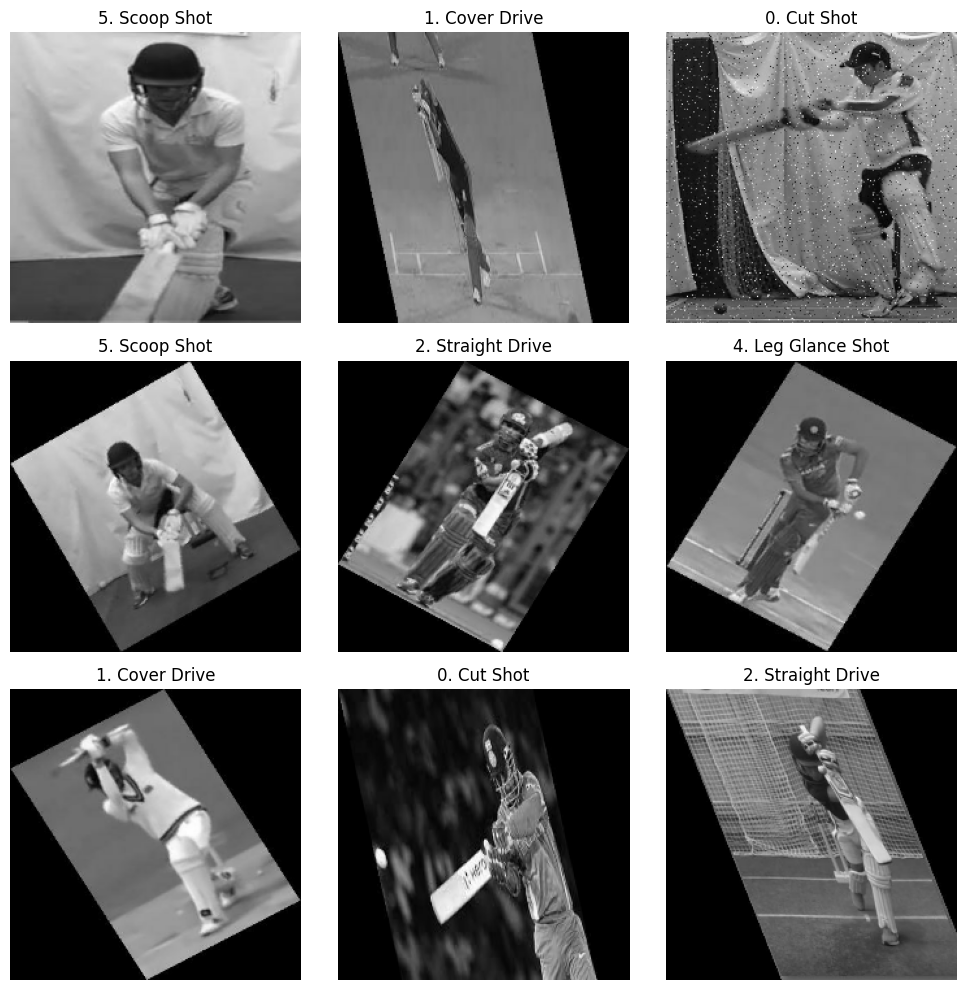

In [7]:
plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        label_idx = np.argmax(labels[i].numpy())
        plt.title(class_names[label_idx])
        plt.axis("off")
plt.tight_layout()
plt.show()


## 6. Data augmentation + preprocessing

EfficientNet expects inputs preprocessed with its own `preprocess_input` (handles scaling internally). We add on-the-fly augmentation for the training set only.

In [8]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
    layers.RandomTranslation(0.1, 0.1),
], name="data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE

def prepare(ds, training=False):
    if training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.cache().prefetch(buffer_size=AUTOTUNE)

train_ds_p = prepare(train_ds, training=True)
val_ds_p = prepare(val_ds, training=False)
test_ds_p = prepare(test_ds, training=False)


## 7. Build the EfficientNetB0 model (transfer learning)

We use `EfficientNetB0` pretrained on ImageNet as a frozen feature extractor, with a custom classification head on top.

In [9]:
def build_model(num_classes, img_size=IMG_SIZE, unfreeze=False):
    base_model = EfficientNetB0(
        include_top=False,
        weights="imagenet",
        input_shape=img_size + (3,)
    )
    base_model.trainable = unfreeze

    inputs = keras.Input(shape=img_size + (3,))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs)
    return model, base_model

model, base_model = build_model(NUM_CLASSES)
model.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,384,169 (16.72 MB)

 Trainable params: 332,038 (1.27 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

## 8. Compile the model

In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


## 9. Callbacks

- `ModelCheckpoint` saves the best model (by val_accuracy) directly to Drive
- `EarlyStopping` stops training if val_loss stops improving (patience is generous since we requested 100 epochs)
- `ReduceLROnPlateau` lowers the learning rate when progress stalls

In [11]:
CHECKPOINT_DIR = "/content/drive/MyDrive/Cricket_Shot_Classification_Model"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(CHECKPOINT_DIR, "best_model_head.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=6,
        min_lr=1e-7,
        verbose=1
    ),
]


## 10. Train the classification head (100 epochs)

The EfficientNet backbone stays **frozen** here; only the new head layers are trained. `EarlyStopping` will stop earlier than 100 epochs if validation loss plateaus, and `restore_best_weights=True` ensures we keep the best-performing weights either way.

In [12]:
history = model.fit(
    train_ds_p,
    validation_data=val_ds_p,
    epochs=EPOCHS_HEAD,
    callbacks=callbacks
)


Epoch 1/100
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 430ms/step - accuracy: 0.3810 - loss: 1.9626
Epoch 1: val_accuracy improved from None to 0.64773, saving model to /content/drive/MyDrive/Cricket_Shot_Classification_Model/best_model_head.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Cricket_Shot_Classification_Model/best_model_head.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 83s 539ms/step - accuracy: 0.4622 - loss: 1.6692 - val_accuracy: 0.6477 - val_loss: 0.9780 - learning_rate: 0.0010
Epoch 2/100
89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.6861 - loss: 0.9028
Epoch 2: val_accuracy improved from 0.64773 to 0.73011, saving model to /content/drive/MyDrive/Cricket_Shot_Classification_Model/best_model_head.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Cricket_Shot_Classification_Model/best_model_head.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 14s 47ms/step - accuracy: 0.6698 - loss: 0.9464 - val_accuracy: 0.7301 - val_loss: 0.7803 - learning_rate: 0.0010
Epoch 3/100
89/90

## 11. Plot training curves

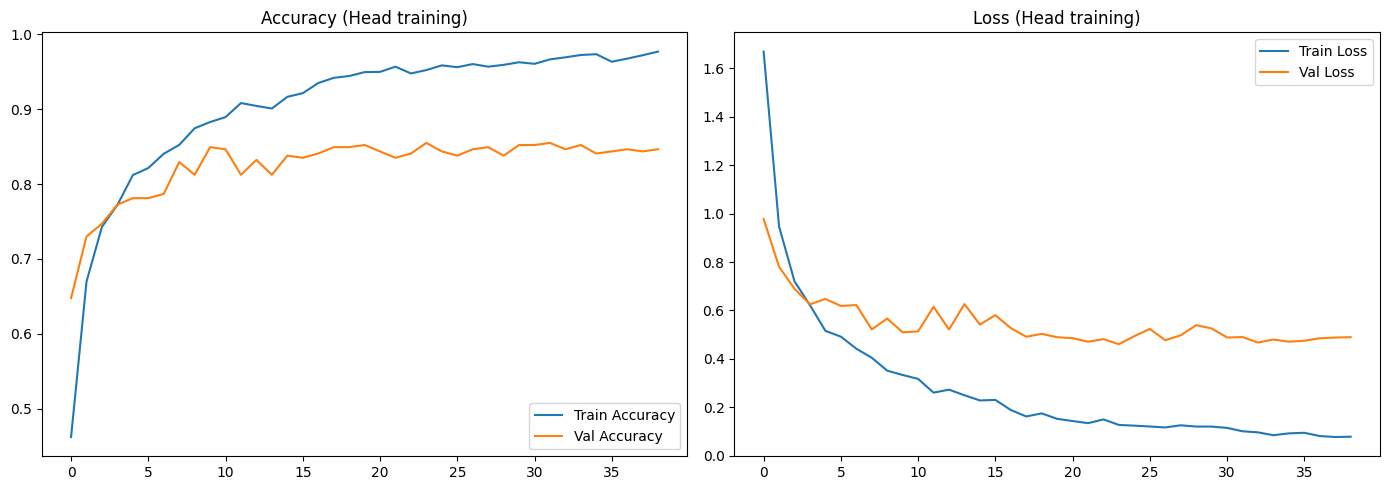

In [13]:
def plot_history(history, title_suffix=""):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(len(acc))

    plt.figure(figsize=(14, 5))

    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Train Accuracy')
    plt.plot(epochs_range, val_acc, label='Val Accuracy')
    plt.legend(loc='lower right')
    plt.title(f'Accuracy {title_suffix}')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Train Loss')
    plt.plot(epochs_range, val_loss, label='Val Loss')
    plt.legend(loc='upper right')
    plt.title(f'Loss {title_suffix}')

    plt.tight_layout()
    plt.show()

plot_history(history, "(Head training)")


## 12. Fine-tuning

Now we unfreeze the top portion of EfficientNetB0 and continue training with a much lower learning rate, to squeeze out extra accuracy.

In [14]:
base_model.trainable = True

# Freeze all layers except the last ~30 (fine-tune only the top blocks)
fine_tune_at = len(base_model.layers) - 30
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(CHECKPOINT_DIR, "best_model_finetuned.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-8,
        verbose=1
    ),
]

history_fine = model.fit(
    train_ds_p,
    validation_data=val_ds_p,
    epochs=EPOCHS_FINE_TUNE,
    callbacks=fine_tune_callbacks
)


Epoch 1/30
90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.7974 - loss: 0.5636
Epoch 1: val_accuracy improved from None to 0.83239, saving model to /content/drive/MyDrive/Cricket_Shot_Classification_Model/best_model_finetuned.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Cricket_Shot_Classification_Model/best_model_finetuned.keras
90/90 ━━━━━━━━━━━━━━━━━━━━ 44s 147ms/step - accuracy: 0.8052 - loss: 0.5571 - val_accuracy: 0.8324 - val_loss: 0.5186 - learning_rate: 1.0000e-05
Epoch 2/30
89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8278 - loss: 0.4763
Epoch 2: val_accuracy did not improve from 0.83239
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8215 - loss: 0.4960 - val_accuracy: 0.8210 - val_loss: 0.5391 - learning_rate: 1.0000e-05
Epoch 3/30
89/90 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.8530 - loss: 0.4291
Epoch 3: val_accuracy did not improve from 0.83239
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 45ms/step - accuracy: 0.8431 - loss: 0.4692 - val_a

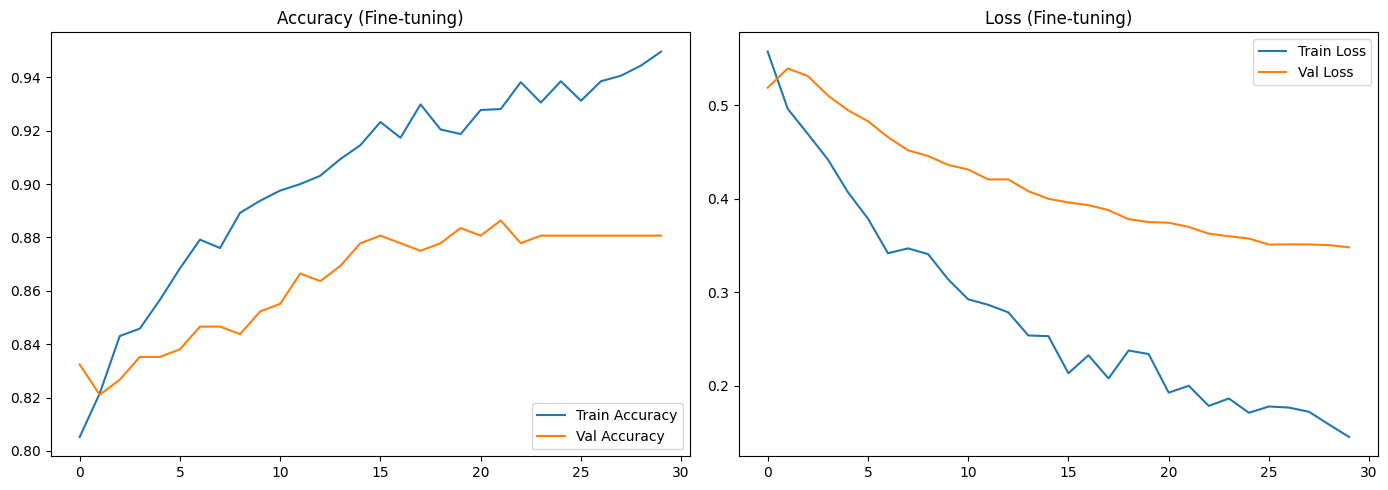

In [15]:
plot_history(history_fine, "(Fine-tuning)")


## 13. Evaluate on the test set

In [16]:
test_loss, test_acc = model.evaluate(test_ds_p)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.9022 - loss: 0.2634
Test Loss: 0.2634
Test Accuracy: 0.9022


### Confusion matrix & classification report

                    precision    recall  f1-score   support

       0. Cut Shot       0.78      0.81      0.80        43
    1. Cover Drive       0.89      0.89      0.89        65
 2. Straight Drive       0.92      0.91      0.91        64
      3. Pull Shot       0.87      0.88      0.87        59
4. Leg Glance Shot       0.93      0.95      0.94        65
     5. Scoop Shot       0.99      0.93      0.96        72

          accuracy                           0.90       368
         macro avg       0.89      0.90      0.90       368
      weighted avg       0.90      0.90      0.90       368



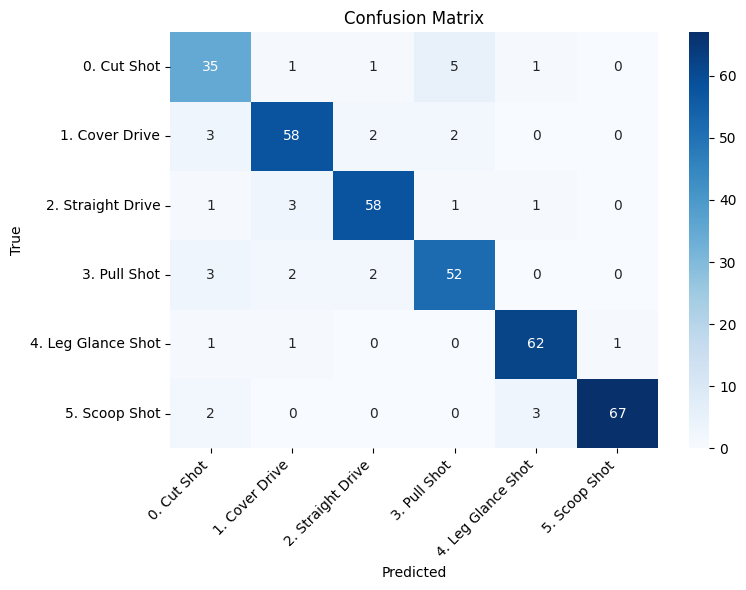

In [17]:
y_true = []
y_pred = []

for images, labels in test_ds_p:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 14. Save the final model to Google Drive

In [18]:
FINAL_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "cricket_shot_efficientnet_final.keras")
model.save(FINAL_MODEL_PATH)
print(f"Model saved to: {FINAL_MODEL_PATH}")

# Also save class names for inference later
import json as _json
with open(os.path.join(CHECKPOINT_DIR, "class_names.json"), "w") as f:
    _json.dump(class_names, f)
print("Class names saved.")


Model saved to: /content/drive/MyDrive/Cricket_Shot_Classification_Model/cricket_shot_efficientnet_final.keras
Class names saved.


## 15. Run inference on a single image

Use this to test the trained model on any new image.

In [19]:
def predict_shot(img_path, model=model, class_names=class_names, img_size=IMG_SIZE):
    img = keras.utils.load_img(img_path, target_size=img_size)
    img_array = keras.utils.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    preds = model.predict(img_array, verbose=0)[0]
    top_idx = np.argmax(preds)

    plt.imshow(img)
    plt.axis("off")
    plt.title(f"Predicted: {class_names[top_idx]} ({preds[top_idx]*100:.1f}%)")
    plt.show()

    for i, cname in enumerate(class_names):
        print(f"{cname}: {preds[i]*100:.2f}%")

    return class_names[top_idx]

# Example usage (uncomment and set a real path):
# predict_shot("/content/drive/MyDrive/Cricket Shot Classification/1. Cover Drive/sample.jpg")


---
### Notes
- If you hit an **out-of-memory** error, lower `BATCH_SIZE` (e.g. to 16).
- If a class has very few images, consider adding more augmentation or collecting more data — CNNs need a reasonable number of samples per class (ideally 200+).
- The `EarlyStopping` callback means training may stop before all 100 epochs if validation loss plateaus; this is intentional and prevents overfitting. Remove/raise `patience` if you want it to run closer to the full 100 epochs regardless.
- Everything (checkpoints, final model, class names) is saved under: `/content/drive/MyDrive/Cricket_Shot_Classification_Model/`
